# AI-Based Ring Artifact Detection and Removal in CT

**Name:** Ekta Chahal &nbsp;|&nbsp; **Roll No:** 24324011 &nbsp;|&nbsp; Department of Physics, IIT Roorkee



In [ ]:
import os, time, json
import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
from scipy.ndimage import map_coordinates, median_filter
from skimage.metrics import peak_signal_noise_ratio as psnr, structural_similarity as ssim


try:
    from google.colab import drive
    drive.mount('/content/drive')
    DATA = '/content/drive/MyDrive/ring_dataset_v2/'
    OUT  = '/content/drive/MyDrive/ring_project_results_v2/'
except ImportError:
    DATA, OUT = './ring_dataset_v2/', './ring_project_results_v2/'
os.makedirs(OUT, exist_ok=True)

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Using device:', device, '(should say cuda for fast training)')
torch.manual_seed(0); np.random.seed(0)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Using device: cuda (should say cuda for fast training)


In [ ]:
def load(split):
    d = np.load(DATA + f'{split}.npz')
    return d['corrupted'], d['clean'], d['ring_mask']

Xtr, Ytr, Mtr = load('train')
Xva, Yva, Mva = load('val')
Xte, Yte, Mte = load('test')
meta_te = json.load(open(DATA + 'test_meta.json'))
print('train', Xtr.shape, '| val', Xva.shape, '| test', Xte.shape)
print('fraction of pixels that are ring (train):', round(float(Mtr.mean()), 4))

train (1000, 256, 256) | val (100, 256, 256) | test (100, 256, 256)
fraction of pixels that are ring (train): 0.078


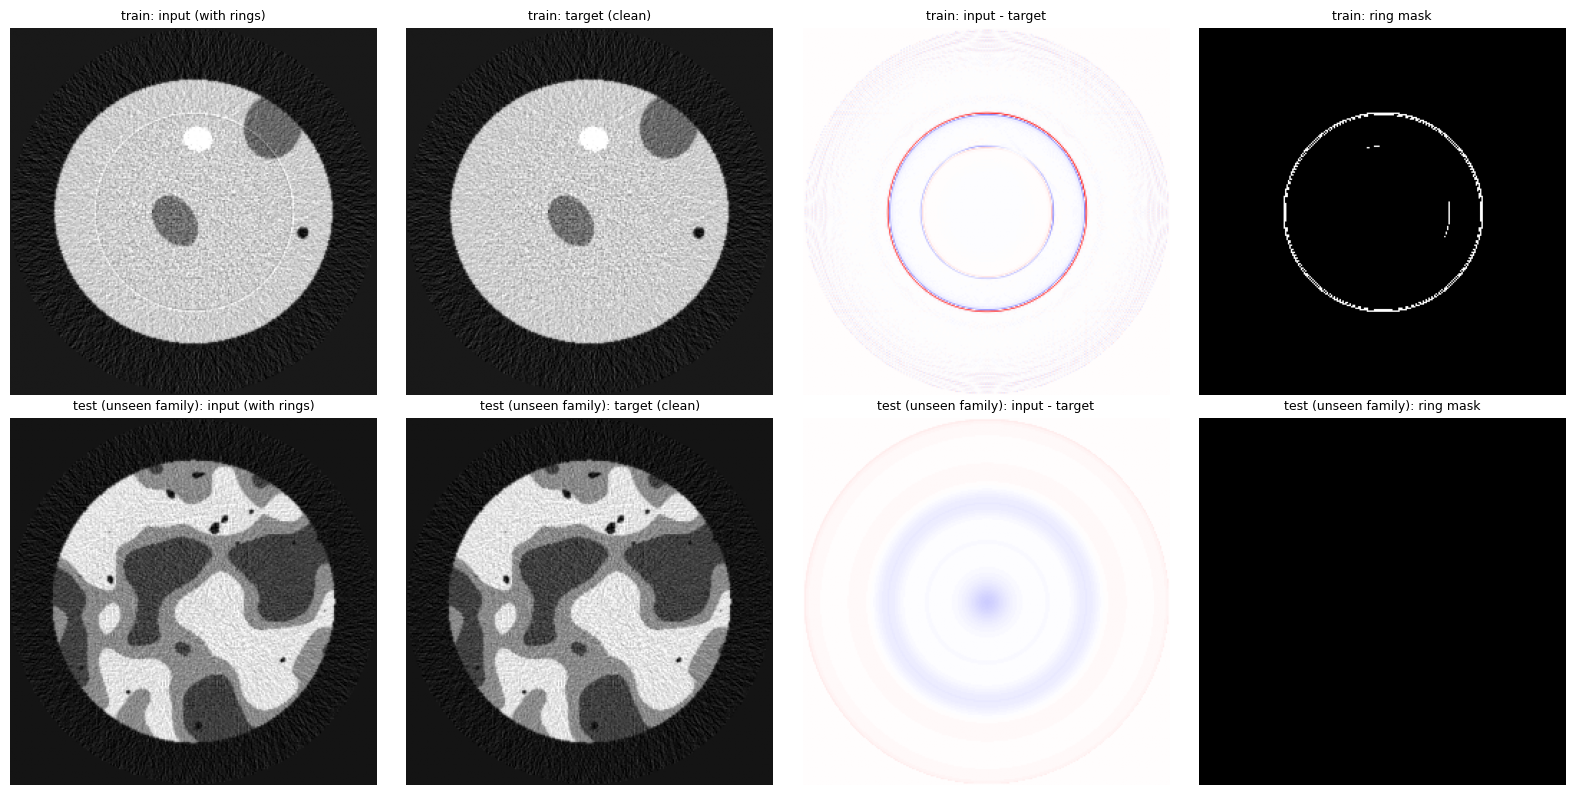

In [ ]:
fig, ax = plt.subplots(2, 4, figsize=(16, 8))
for r, (X, Y, M, name) in enumerate([(Xtr, Ytr, Mtr, 'train'), (Xte, Yte, Mte, 'test (unseen family)')]):
    i = 3
    lo, hi = np.percentile(Y[i], [1, 99.5])
    for a, im, t, kw in zip(ax[r], [X[i], Y[i], X[i] - Y[i], M[i]],
                            ['input (with rings)', 'target (clean)', 'input - target', 'ring mask'],
                            [dict(vmin=lo, vmax=hi), dict(vmin=lo, vmax=hi), dict(vmin=-.3, vmax=.3, cmap='seismic'), {}]):
        kw.setdefault('cmap', 'gray'); a.imshow(im, **kw); a.set_title(f'{name}: {t}', fontsize=9); a.axis('off')
plt.tight_layout(); plt.savefig(OUT + 'fig_data_examples.png', dpi=110); plt.show()

In [ ]:
def remove_rings_classical(img, n_theta=720, window=5, k=6):
    n = img.shape[0]; c = (n - 1) / 2
    radii = np.arange(0, int(c)); theta = np.linspace(0, 2*np.pi, n_theta, endpoint=False)
    rr, tt = np.meshgrid(radii, theta, indexing='ij')
    polar = map_coordinates(img, [c + rr*np.sin(tt), c + rr*np.cos(tt)], order=1)
    profile = np.median(polar, axis=1)
    ring_profile = profile - median_filter(profile, size=window)
    mad = np.median(np.abs(ring_profile - np.median(ring_profile))) + 1e-9
    ring_profile = np.where(np.abs(ring_profile) < k * 1.4826 * mad, ring_profile, 0.0)
    y, x = np.mgrid[0:n, 0:n]
    ring_est = np.interp(np.sqrt((x - c)**2 + (y - c)**2), radii, ring_profile, right=0)
    return img - ring_est, ring_est

In [ ]:
def val_psnr(w, k):
    s = []
    for i in range(len(Xva)):
        dr = float(Yva[i].max() - Yva[i].min())
        fixed, _ = remove_rings_classical(Xva[i], window=w, k=k)
        s.append(psnr(Yva[i], fixed, data_range=dr))
    return np.mean(s)

grid = {(w, k): val_psnr(w, k) for w in [3, 5, 9, 15, 25] for k in [3, 6, 10]}
for key, v in sorted(grid.items(), key=lambda t: -t[1])[:5]:
    print(key, round(v, 2))
BEST_W, BEST_K = max(grid, key=grid.get)
print('best (window, k):', BEST_W, BEST_K)

(25, 10) 34.57
(25, 6) 34.54
(15, 10) 34.47
(25, 3) 34.44
(15, 6) 34.43
best (window, k): 25 10


In [ ]:
grid2 = {}
for w in [25, 41, 61, 81]:
    for k in [10, 15, 20, 30]:
        grid2[(w, k)] = val_psnr(w, k)
        print(w, k, round(grid2[(w, k)], 2))

BEST_W, BEST_K = max(grid2, key=grid2.get)
print('best (window, k):', BEST_W, BEST_K, round(grid2[(BEST_W, BEST_K)], 2))

25 10 34.57
25 15 34.63
25 20 34.67
25 30 34.72
41 10 34.38
41 15 34.42
41 20 34.46
41 30 34.52
61 10 33.9
61 15 33.89
61 20 33.87
61 30 33.79
81 10 33.36
81 15 33.11
81 20 32.35
81 30 32.01
best (window, k): 25 30 34.72


In [ ]:
class RingDS(torch.utils.data.Dataset):
    def __init__(self, X, Y, M, aug=False):
        self.X, self.Y, self.M, self.aug = X, Y, M, aug
    def __len__(self): return len(self.X)
    def __getitem__(self, i):
        x = torch.from_numpy(self.X[i])[None]; y = torch.from_numpy(self.Y[i])[None]
        m = torch.from_numpy(self.M[i].astype(np.float32))[None]
        if self.aug:
            k = int(np.random.randint(4))
            x, y, m = [torch.rot90(t, k, (1, 2)) for t in (x, y, m)]
            if np.random.rand() < 0.5: x, y, m = [torch.flip(t, (2,)) for t in (x, y, m)]
        return x, x - y, m

def block(i, o):
    return nn.Sequential(nn.Conv2d(i, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU(True),
                         nn.Conv2d(o, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU(True))

class UNet(nn.Module):
    def __init__(self, base=32):
        super().__init__()
        c = [base, base*2, base*4, base*8]
        self.e1, self.e2, self.e3, self.b = block(1, c[0]), block(c[0], c[1]), block(c[1], c[2]), block(c[2], c[3])
        self.u3, self.d3 = nn.ConvTranspose2d(c[3], c[2], 2, 2), block(c[3], c[2])
        self.u2, self.d2 = nn.ConvTranspose2d(c[2], c[1], 2, 2), block(c[2], c[1])
        self.u1, self.d1 = nn.ConvTranspose2d(c[1], c[0], 2, 2), block(c[1], c[0])
        self.out = nn.Conv2d(c[0], 2, 1)
    def forward(self, x):
        e1 = self.e1(x); e2 = self.e2(F.max_pool2d(e1, 2)); e3 = self.e3(F.max_pool2d(e2, 2))
        b = self.b(F.max_pool2d(e3, 2))
        d3 = self.d3(torch.cat([self.u3(b), e3], 1))
        d2 = self.d2(torch.cat([self.u2(d3), e2], 1))
        d1 = self.d1(torch.cat([self.u1(d2), e1], 1))
        o = self.out(d1)
        return o[:, :1], o[:, 1:]

model = UNet().to(device)
print('trainable parameters:', sum(p.numel() for p in model.parameters() if p.requires_grad))

trainable parameters: 1927874


/tmp/ipykernel_2771/3233965524.py:48: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scaler.step(opt); scaler.update(); sched.step()


[unet_best] epoch 01/60  train 2.6365  val 1.9755  (15s)
[unet_best] epoch 02/60  train 1.7802  val 1.6675  (26s)
[unet_best] epoch 03/60  train 1.5868  val 1.5094  (37s)
[unet_best] epoch 04/60  train 1.4732  val 1.4192  (48s)
[unet_best] epoch 05/60  train 1.3876  val 1.3620  (59s)
[unet_best] epoch 06/60  train 1.3033  val 1.2940  (71s)
[unet_best] epoch 07/60  train 1.2322  val 1.2332  (82s)
[unet_best] epoch 08/60  train 1.1638  val 1.1228  (94s)
[unet_best] epoch 09/60  train 1.0783  val 1.0836  (106s)
[unet_best] epoch 10/60  train 1.0178  val 1.0990  (118s)
[unet_best] epoch 11/60  train 0.9680  val 0.9480  (130s)
[unet_best] epoch 12/60  train 0.9301  val 0.9706  (142s)
[unet_best] epoch 13/60  train 0.8998  val 0.9039  (154s)
[unet_best] epoch 14/60  train 0.8626  val 0.8817  (165s)
[unet_best] epoch 15/60  train 0.8394  val 0.8788  (177s)
[unet_best] epoch 16/60  train 0.8086  val 0.8414  (189s)
[unet_best] epoch 17/60  train 0.7913  val 0.7884  (201s)
[unet_best] epoch 18/6

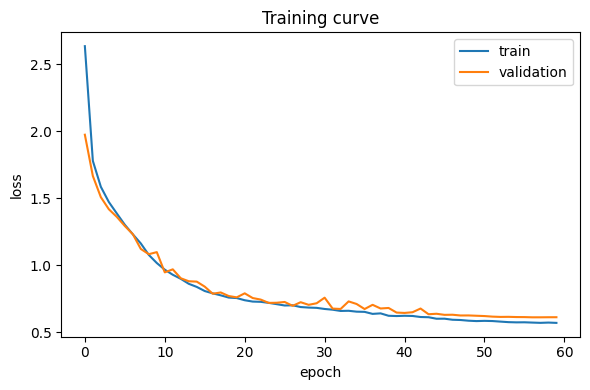

In [ ]:
EPOCHS, BATCH, LR = 60, 8, 1e-3
use_amp = (device == 'cuda')


dl_va = torch.utils.data.DataLoader(RingDS(Xva, Yva, Mva, aug=False), batch_size=BATCH, shuffle=False)


def dice_loss(logits, m, eps=1e-6):
    p = torch.sigmoid(logits)
    return 1 - (2 * (p * m).sum((1, 2, 3)) + eps) / (p.sum((1, 2, 3)) + m.sum((1, 2, 3)) + eps)


def train_model(tag, n_train=None, seed=0, epochs=EPOCHS, use_dice=True):
    """Train one U-Net and keep the weights with the lowest validation loss.
    tag      : name of the saved weights file (OUT + tag + '.pt')
    n_train  : use only this many training images (None = all)
    use_dice : False drops the Dice term from the loss (for the ablation)"""
    torch.manual_seed(seed); np.random.seed(seed)


    idx = np.random.RandomState(seed).permutation(len(Xtr))[:n_train or len(Xtr)]
    dl_t = torch.utils.data.DataLoader(RingDS(Xtr[idx], Ytr[idx], Mtr[idx], aug=True),
                                       batch_size=BATCH, shuffle=True, drop_last=True)

    net = UNet().to(device)
    opt = torch.optim.AdamW(net.parameters(), lr=LR, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=LR, total_steps=epochs * len(dl_t))
    scaler = torch.amp.GradScaler(enabled=use_amp)

    def lossf(res, lg, rt, m):
        l = F.l1_loss(res, rt) * 10 + F.binary_cross_entropy_with_logits(lg, m)
        if use_dice:
            l = l + dice_loss(lg, m).mean()
        return l

    hist = {'train': [], 'val': []}
    best = 1e9
    t0 = time.time()
    for ep in range(epochs):
        net.train(); tl = 0
        for x, rt, m in dl_t:
            x, rt, m = x.to(device), rt.to(device), m.to(device)
            with torch.autocast(device_type=device, enabled=use_amp):
                res, lg = net(x)
            loss = lossf(res.float(), lg.float(), rt, m)
            opt.zero_grad()
            scaler.scale(loss).backward()
            scaler.step(opt); scaler.update(); sched.step()
            tl += loss.item()

        net.eval(); vl = 0
        with torch.no_grad():
            for x, rt, m in dl_va:
                x, rt, m = x.to(device), rt.to(device), m.to(device)
                res, lg = net(x)
                vl += lossf(res, lg, rt, m).item()

        tl /= len(dl_t); vl /= len(dl_va)
        hist['train'].append(tl); hist['val'].append(vl)
        if vl < best:
            best = vl
            torch.save(net.state_dict(), OUT + tag + '.pt')
        print(f'[{tag}] epoch {ep+1:02d}/{epochs}  train {tl:.4f}  val {vl:.4f}  ({time.time()-t0:.0f}s)')
    return hist


def load_weights(tag):
    """Put the saved weights into the global `model` that evaluate() uses."""
    global model
    model = UNet().to(device)
    model.load_state_dict(torch.load(OUT + tag + '.pt', map_location=device))
    model.eval()



hist = train_model('unet_best')

plt.figure(figsize=(6, 4))
plt.plot(hist['train'], label='train')
plt.plot(hist['val'], label='validation')
plt.xlabel('epoch'); plt.ylabel('loss'); plt.legend(); plt.title('Training curve')
plt.tight_layout()
plt.savefig(OUT + 'fig_training_curve.png', dpi=110)
plt.show()




In [ ]:
load_weights('unet_best')

def dice_np(a, b):
    if a.sum() + b.sum() == 0:
        return np.nan
    return 2 * (a & b).sum() / (a.sum() + b.sum())

@torch.no_grad()
def unet_predict(X, bs=16, thr=0.5):
    R, P = [], []
    for i in range(0, len(X), bs):
        x = torch.from_numpy(X[i:i+bs])[:, None].to(device)
        res, lg = model(x); R.append(res[:, 0].cpu().numpy()); P.append((torch.sigmoid(lg[:, 0]) > thr).cpu().numpy())
    return np.concatenate(R), np.concatenate(P)

def evaluate(X, Y, M):
    Rn, Pn = unet_predict(X)
    rows = {'Input': [], 'Classical': [], 'U-Net': []}
    per_img = []
    for i in range(len(X)):
        dr = float(Y[i].max() - Y[i].min())
        fixed_c, est_c = remove_rings_classical(X[i], window=BEST_W, k=BEST_K)
        fixed_n = X[i] - Rn[i]
        mt = M[i].astype(bool); mc = np.abs(est_c) > 0.04 * dr
        r = {'Input':     (psnr(Y[i], X[i], data_range=dr),     ssim(Y[i], X[i], data_range=dr),     np.nan),
             'Classical': (psnr(Y[i], fixed_c, data_range=dr),  ssim(Y[i], fixed_c, data_range=dr),  dice_np(mc, mt)),
             'U-Net':     (psnr(Y[i], fixed_n, data_range=dr),  ssim(Y[i], fixed_n, data_range=dr),  dice_np(Pn[i].astype(bool), mt))}
        for k in rows: rows[k].append(r[k])
        per_img.append(r)
    return {k: np.nanmean(np.array(v), axis=0) for k, v in rows.items()}, per_img, Rn, Pn

def show(name, res):
    print(f'\n=== {name} ===')
    print(f"{'method':<10} {'PSNR (dB)':>10} {'SSIM':>8} {'Dice':>8}")
    for k, v in res.items(): print(f'{k:<10} {v[0]:>10.2f} {v[1]:>8.4f} {v[2]:>8.3f}')

res_va, _, _, _                    = evaluate(Xva, Yva, Mva);  show('Validation (same phantom family as training)', res_va)
res_te, per_te, Rte, Pte           = evaluate(Xte, Yte, Mte);  show('TEST (unseen phantom family)', res_te)

import csv
with open(OUT + 'results.csv', 'w', newline='') as f:
    w = csv.writer(f); w.writerow(['split', 'method', 'PSNR', 'SSIM', 'Dice'])
    for nm, rs in [('val', res_va), ('test', res_te)]:
        for k, v in rs.items(): w.writerow([nm, k, round(v[0], 3), round(v[1], 4), None if np.isnan(v[2]) else round(v[2], 4)])

/tmp/ipykernel_2771/227382387.py:30: RuntimeWarning: Mean of empty slice
  return {k: np.nanmean(np.array(v), axis=0) for k, v in rows.items()}, per_img, Rn, Pn



=== Validation (same phantom family as training) ===
method      PSNR (dB)     SSIM     Dice
Input           33.95   0.8702      nan
Classical       34.72   0.8877    0.154
U-Net           40.81   0.9591    0.668

=== TEST (unseen phantom family) ===
method      PSNR (dB)     SSIM     Dice
Input           33.11   0.8678      nan
Classical       32.55   0.8783    0.218
U-Net           39.54   0.9565    0.640


In [ ]:
for t in [0.3, 0.4, 0.5, 0.6, 0.7]:
    _, Pv = unet_predict(Xva, thr=t)
    d = [dice_np(Pv[i], Mva[i].astype(bool)) for i in range(len(Xva))]
    print(t, round(float(np.nanmean(d)), 3))

0.3 0.657
0.4 0.66
0.5 0.668
0.6 0.674
0.7 0.668


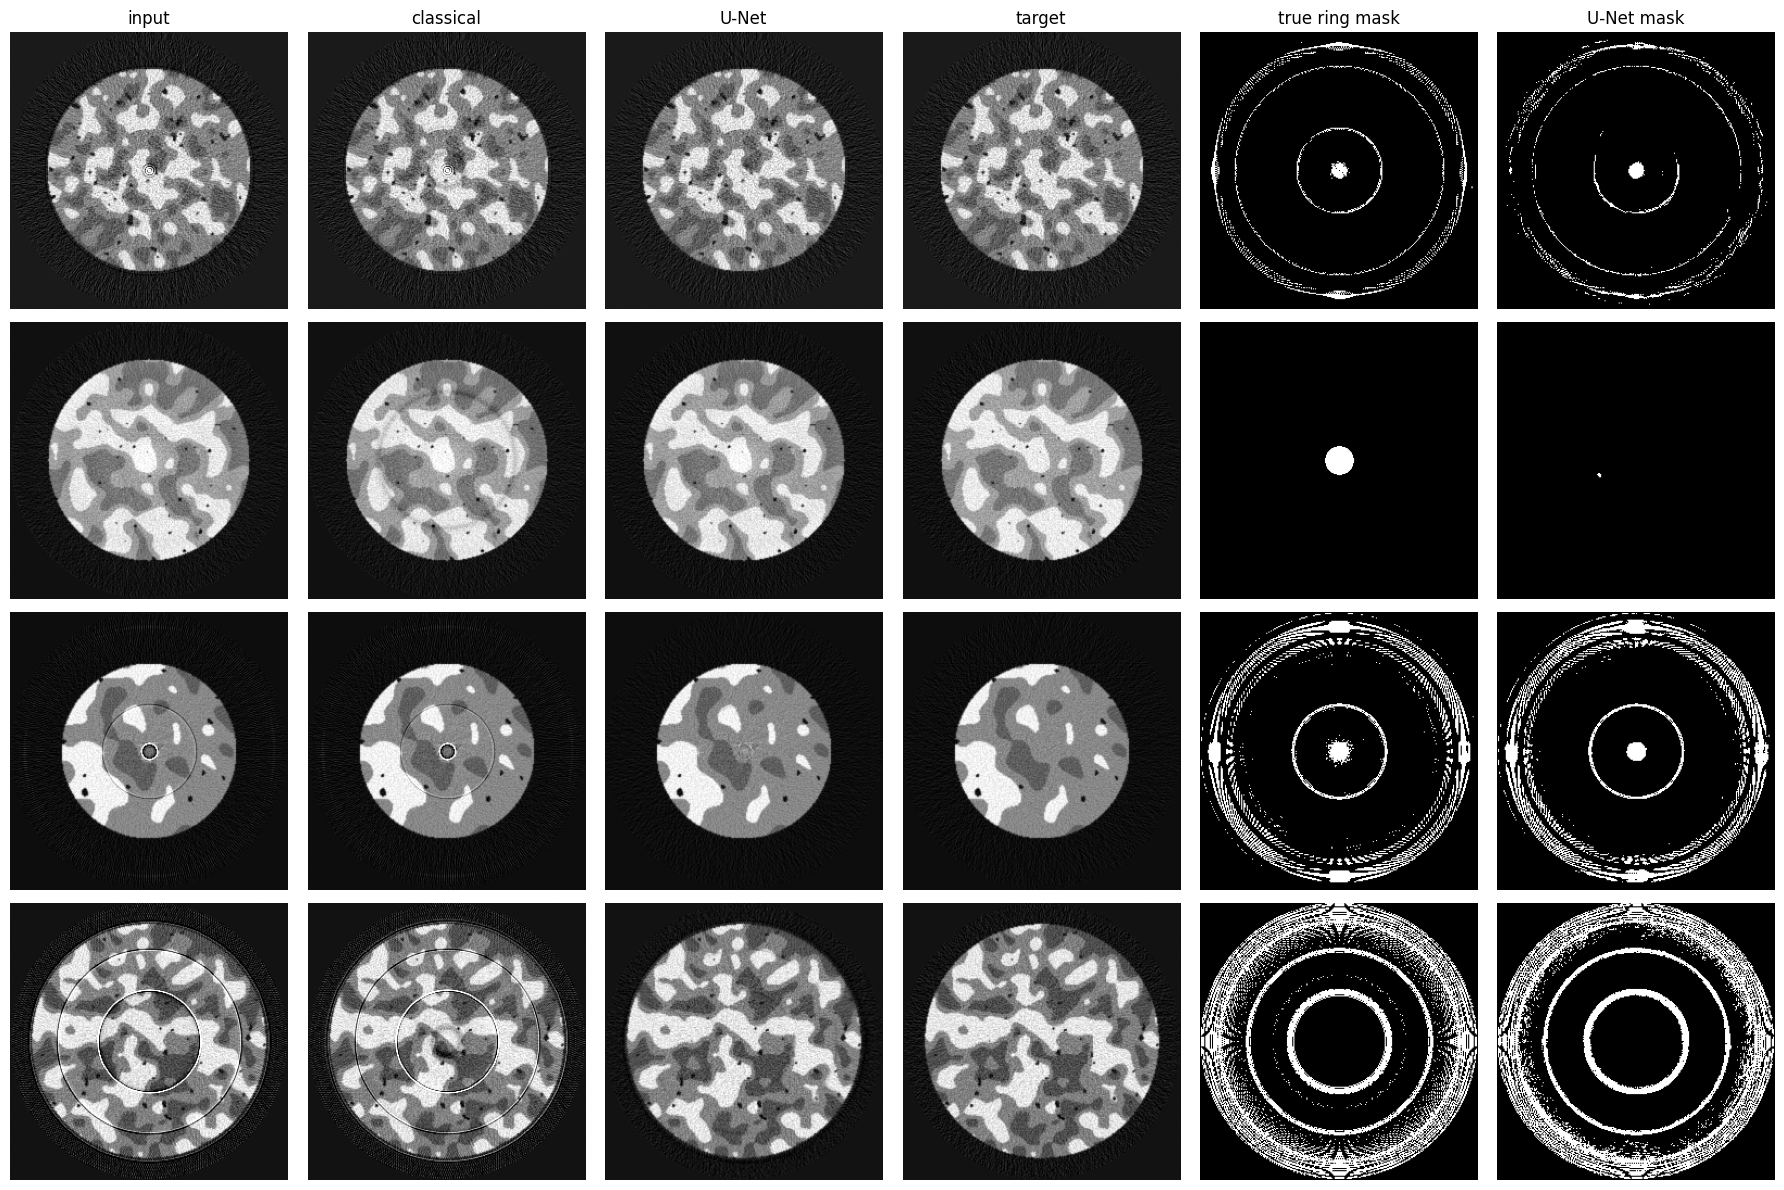

In [ ]:
idx = [0, 5, 10, 15]
fig, ax = plt.subplots(len(idx), 6, figsize=(18, 3*len(idx)))
for r, i in enumerate(idx):
    fixed_c, _ = remove_rings_classical(Xte[i], window=BEST_W, k=BEST_K); fixed_n = Xte[i] - Rte[i]
    lo, hi = np.percentile(Yte[i], [1, 99.5])
    ims = [Xte[i], fixed_c, fixed_n, Yte[i], Mte[i], Pte[i]]
    ts  = ['input', 'classical', 'U-Net', 'target', 'true ring mask', 'U-Net mask']
    for j, (im, t) in enumerate(zip(ims, ts)):
        kw = dict(vmin=lo, vmax=hi) if j < 4 else {}
        ax[r, j].imshow(im, cmap='gray', **kw); ax[r, j].axis('off')
        if r == 0: ax[r, j].set_title(t)
plt.tight_layout(); plt.savefig(OUT + 'fig_test_comparison.png', dpi=100); plt.show()

In [ ]:
kinds = sorted(set(m['ring_kind'] for m in meta_te))

def avg(vals):

    vals = [v for v in vals if not np.isnan(v)]
    return float(np.mean(vals)) if vals else float('nan')

print(f"{'ring type':<15} {'n':>3} {'PSNR input':>11} {'PSNR classical':>15} {'PSNR U-Net':>11} {'Dice classical':>15} {'Dice U-Net':>11}")
for k in kinds:
    ids = [i for i, m in enumerate(meta_te) if m['ring_kind'] == k]
    p = {a: np.mean([per_te[i][a][0] for i in ids]) for a in ['Input', 'Classical', 'U-Net']}
    d = {a: avg([per_te[i][a][2] for i in ids]) for a in ['Classical', 'U-Net']}
    print(f"{k:<15} {len(ids):>3} {p['Input']:>11.2f} {p['Classical']:>15.2f} {p['U-Net']:>11.2f} {d['Classical']:>15.3f} {d['U-Net']:>11.3f}")

ring type         n  PSNR input  PSNR classical  PSNR U-Net  Dice classical  Dice U-Net
band             21       45.91           42.32       46.32           0.001       0.066
dead_hot         17       20.80           21.15       34.69           0.302       0.813
many_mild        26       34.02           34.01       38.39           0.157       0.631
mixed            13       28.55           29.40       35.78           0.319       0.724
sparse_strong    23       32.07           32.20       40.36           0.261       0.798


In [1]:

size_rows = []
for n in [100, 500, 1000]:
    train_model(f'n{n}', n_train=n)
    load_weights(f'n{n}')
    r, *_ = evaluate(Xte, Yte, Mte)
    size_rows.append((n, *[round(float(v), 4) for v in r['U-Net']]))
    print(size_rows[-1])

NameError: name 'train_model' is not defined

In [ ]:
seed_psnr = []
for s in [1, 2]:
    train_model(f'seed{s}', seed=s)
    load_weights(f'seed{s}')
    r, *_ = evaluate(Xte, Yte, Mte)
    seed_psnr.append(r['U-Net'][0])
print(seed_psnr)

/tmp/ipykernel_2771/3233965524.py:48: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scaler.step(opt); scaler.update(); sched.step()


[seed1] epoch 01/60  train 3.0106  val 1.9872  (11s)
[seed1] epoch 02/60  train 1.8179  val 1.7260  (22s)
[seed1] epoch 03/60  train 1.6747  val 1.6224  (33s)
[seed1] epoch 04/60  train 1.6101  val 1.5807  (44s)
[seed1] epoch 05/60  train 1.5495  val 1.5064  (55s)
[seed1] epoch 06/60  train 1.4773  val 1.4294  (66s)
[seed1] epoch 07/60  train 1.4021  val 1.3696  (78s)
[seed1] epoch 08/60  train 1.3209  val 1.2974  (89s)
[seed1] epoch 09/60  train 1.2516  val 1.2499  (101s)
[seed1] epoch 10/60  train 1.1953  val 1.1547  (112s)
[seed1] epoch 11/60  train 1.1184  val 1.0674  (123s)
[seed1] epoch 12/60  train 1.0607  val 1.0268  (134s)
[seed1] epoch 13/60  train 1.0091  val 0.9980  (146s)
[seed1] epoch 14/60  train 0.9500  val 0.9462  (157s)
[seed1] epoch 15/60  train 0.9078  val 0.9029  (168s)
[seed1] epoch 16/60  train 0.8664  val 0.8283  (180s)
[seed1] epoch 17/60  train 0.8441  val 0.8600  (191s)
[seed1] epoch 18/60  train 0.8189  val 0.8448  (202s)
[seed1] epoch 19/60  train 0.7975  v

/tmp/ipykernel_2771/227382387.py:30: RuntimeWarning: Mean of empty slice
  return {k: np.nanmean(np.array(v), axis=0) for k, v in rows.items()}, per_img, Rn, Pn


[seed2] epoch 01/60  train 3.1040  val 2.0209  (11s)
[seed2] epoch 02/60  train 1.7903  val 1.6939  (23s)
[seed2] epoch 03/60  train 1.6572  val 1.6168  (34s)
[seed2] epoch 04/60  train 1.5703  val 1.5267  (46s)
[seed2] epoch 05/60  train 1.5068  val 1.4802  (57s)
[seed2] epoch 06/60  train 1.4429  val 1.3946  (68s)
[seed2] epoch 07/60  train 1.3716  val 1.3431  (80s)
[seed2] epoch 08/60  train 1.3028  val 1.2706  (91s)
[seed2] epoch 09/60  train 1.2347  val 1.3051  (102s)
[seed2] epoch 10/60  train 1.1676  val 1.1236  (113s)
[seed2] epoch 11/60  train 1.0867  val 1.0448  (125s)
[seed2] epoch 12/60  train 1.0379  val 1.0501  (136s)
[seed2] epoch 13/60  train 1.0110  val 0.9824  (147s)
[seed2] epoch 14/60  train 0.9637  val 0.9285  (158s)
[seed2] epoch 15/60  train 0.9101  val 0.9172  (170s)
[seed2] epoch 16/60  train 0.8660  val 0.9459  (181s)
[seed2] epoch 17/60  train 0.8354  val 0.8211  (192s)
[seed2] epoch 18/60  train 0.8127  val 0.7861  (204s)
[seed2] epoch 19/60  train 0.7989  v

In [ ]:
train_model('nodice', use_dice=False)
load_weights('nodice')
r, *_ = evaluate(Xte, Yte, Mte)
show('TEST, no Dice term', r)

/tmp/ipykernel_2771/3233965524.py:48: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scaler.step(opt); scaler.update(); sched.step()


[nodice] epoch 01/60  train 1.7660  val 1.1075  (11s)
[nodice] epoch 02/60  train 0.9119  val 0.7851  (23s)
[nodice] epoch 03/60  train 0.7101  val 0.6535  (34s)
[nodice] epoch 04/60  train 0.6101  val 0.5522  (45s)
[nodice] epoch 05/60  train 0.5361  val 0.5250  (57s)
[nodice] epoch 06/60  train 0.4836  val 0.4619  (68s)
[nodice] epoch 07/60  train 0.4429  val 0.4174  (79s)
[nodice] epoch 08/60  train 0.4085  val 0.3932  (91s)
[nodice] epoch 09/60  train 0.3768  val 0.3391  (102s)
[nodice] epoch 10/60  train 0.3544  val 0.3518  (113s)
[nodice] epoch 11/60  train 0.3351  val 0.3335  (125s)
[nodice] epoch 12/60  train 0.3250  val 0.3764  (136s)
[nodice] epoch 13/60  train 0.3193  val 0.3204  (147s)
[nodice] epoch 14/60  train 0.3016  val 0.3021  (159s)
[nodice] epoch 15/60  train 0.2965  val 0.3209  (170s)
[nodice] epoch 16/60  train 0.2884  val 0.2955  (181s)
[nodice] epoch 17/60  train 0.2841  val 0.2597  (193s)
[nodice] epoch 18/60  train 0.2753  val 0.2568  (204s)
[nodice] epoch 19/

/tmp/ipykernel_2771/349162428.py:30: RuntimeWarning: Mean of empty slice
  return {k: np.nanmean(np.array(v), axis=0) for k, v in rows.items()}, per_img, Rn, Pn
